In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
batch_size = 32
epochs = 10

In [2]:
transform_train = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

transform_test = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = datasets.GTSRB(root='./data', split='train', download=True, transform=transform_train)
test_dataset = datasets.GTSRB(root='./data', split='test', download=True, transform=transform_test)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

num_classes = 43 # O dataset GTSRB possui 43 classes de placas

100%|██████████| 187M/187M [00:19<00:00, 9.56MB/s]
100%|██████████| 89.0M/89.0M [00:17<00:00, 5.22MB/s]
100%|██████████| 99.6k/99.6k [00:00<00:00, 185kB/s]


In [3]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

for param in model.parameters():
    param.requires_grad = False

num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, num_classes)
model = model.to(device)

criterion = nn.CrossEntropyLoss()

# Experimento: Alterne entre Adam e SGD comentando/descomentando as linhas abaixo
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)
# optimizer = optim.SGD(model.fc.parameters(), lr=0.001, momentum=0.9)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 241MB/s]


Época 1/10 - Loss: 1.6166
Época 2/10 - Loss: 0.9413
Época 3/10 - Loss: 0.7799
Época 4/10 - Loss: 0.7035
Época 5/10 - Loss: 0.6486
Época 6/10 - Loss: 0.6145
Época 7/10 - Loss: 0.5863
Época 8/10 - Loss: 0.5679
Época 9/10 - Loss: 0.5396
Época 10/10 - Loss: 0.5325


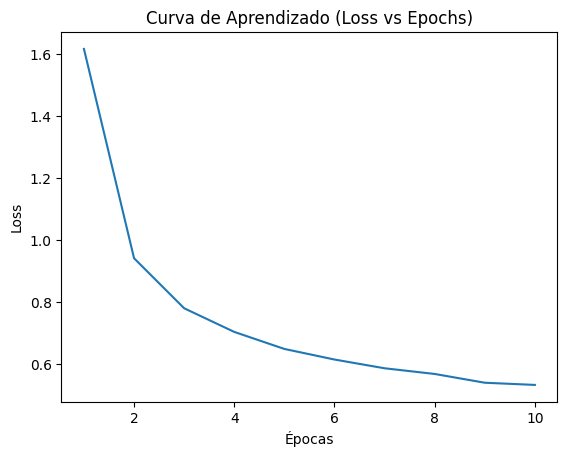

In [4]:
model.train()
loss_history = []

for epoch in range(epochs):
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)
    loss_history.append(epoch_loss)
    print(f"Época {epoch+1}/{epochs} - Loss: {epoch_loss:.4f}")

plt.plot(range(1, epochs + 1), loss_history)
plt.title('Curva de Aprendizado (Loss vs Epochs)')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.show()

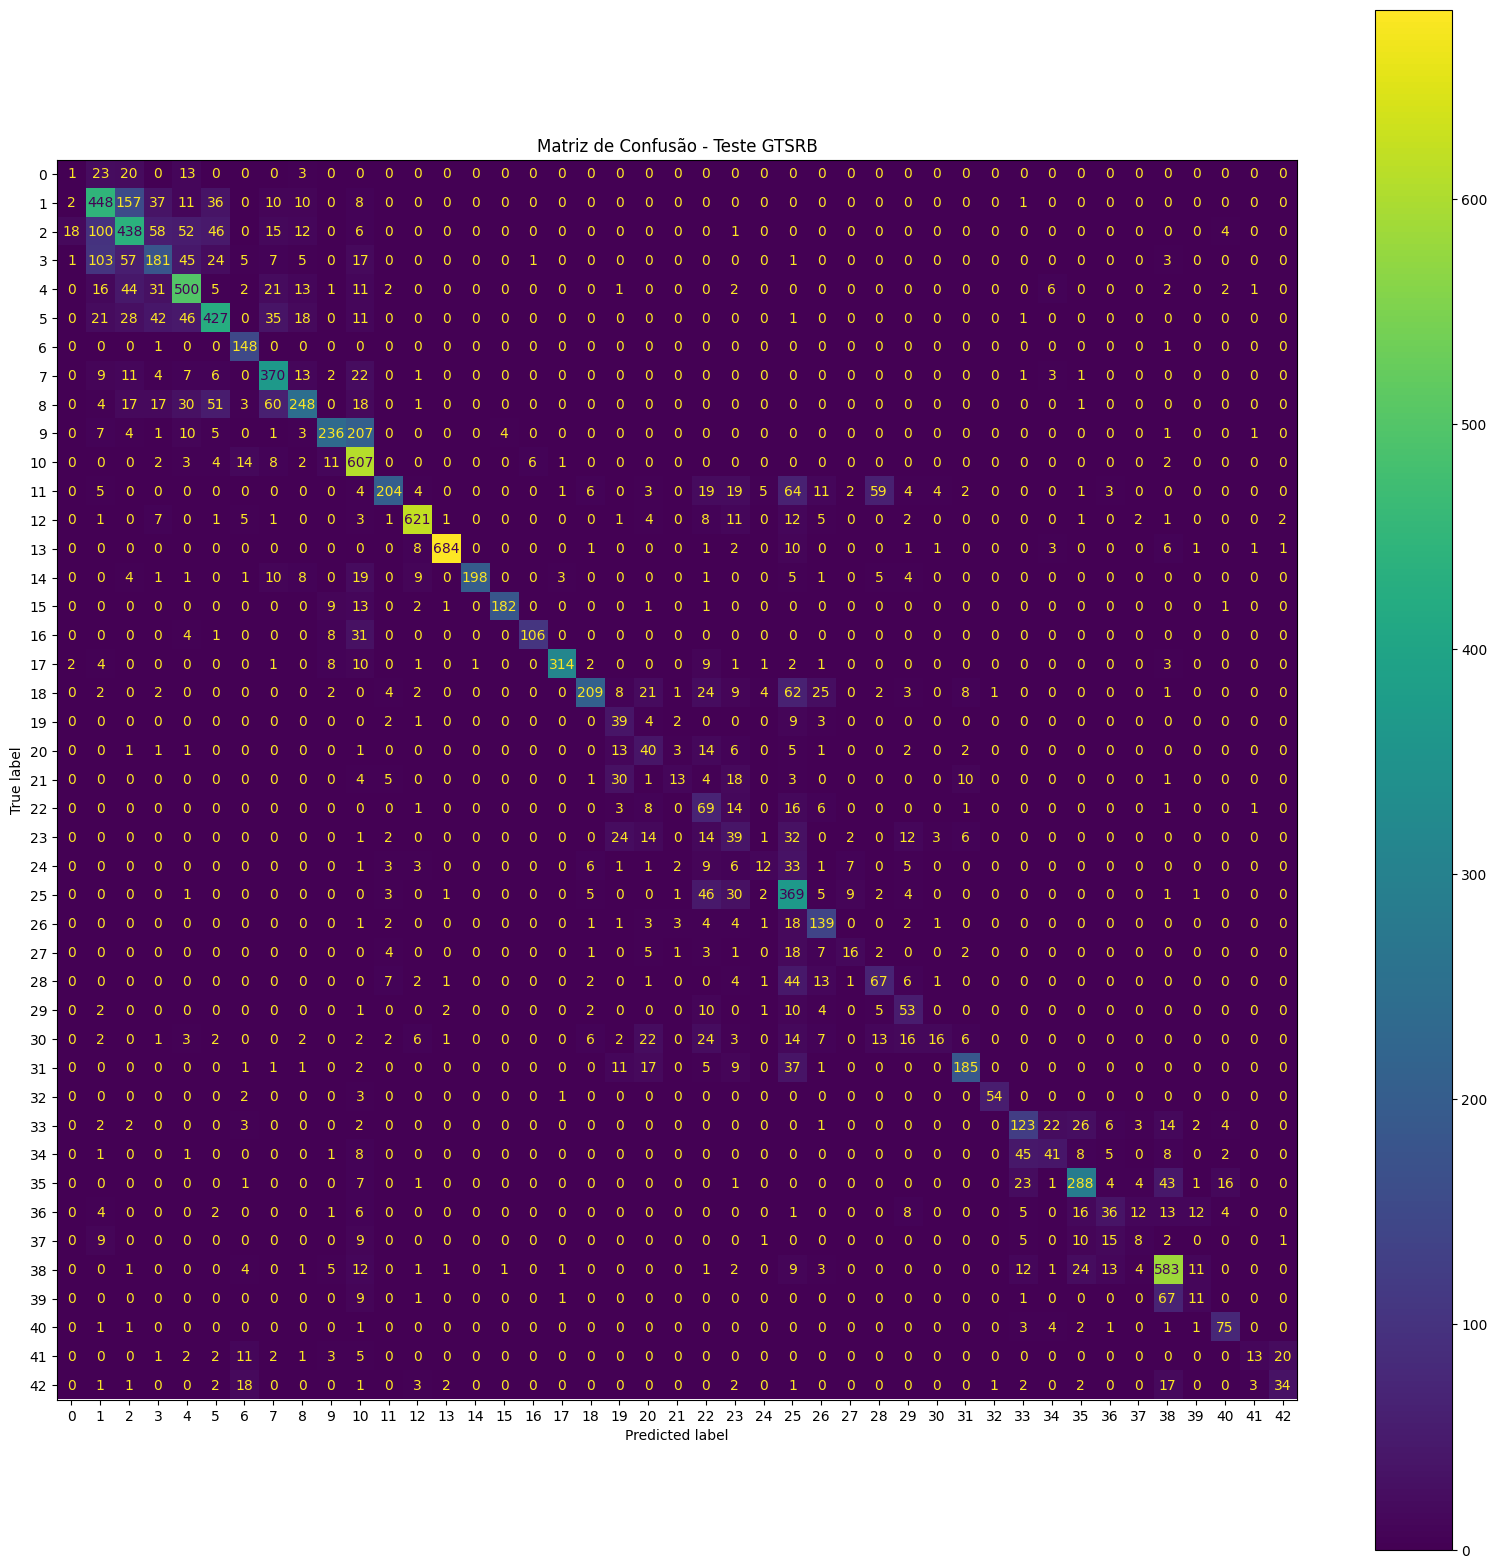

In [5]:
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

cm = confusion_matrix(all_labels, all_preds)
fig, ax = plt.subplots(figsize=(20, 20))
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(ax=ax, cmap='viridis')
plt.title('Matriz de Confusão - Teste GTSRB')
plt.show()